# EN3150: Pattern Recognition & Machine Learning
## Assignment 03: Resource-Constrained CNN for Edge Image Classification
### Model A: Standard Convolutional Neural Network (CNN)

---

### Project Overview & Objectives
This notebook develops and evaluates **Model A**, a standard convolutional neural network designed for edge-device deployment on the German Traffic Sign Recognition Benchmark (GTSRB).

**Key Specifications & Constraints:**
- **Input Resolution:** Downscaled to $64 \times 64$ pixels to emulate a resource-constrained edge sensor environment.
- **Dataset Partitioning:** 70% Training, 15% Validation, and 15% Testing with strictly disjoint splits.
- **Architecture:** Interleaved standard 2D convolutions (`Conv2d`), ReLU activations, and max-pooling (`MaxPool2d`) layers.
- **Parameter Budget:** Sub-100k trainable parameters (Model A achieves 45,643 parameters).
- **Hardware-Aware Design Justification:**
  - Uses **ReLU** activation: Eliminates computationally expensive transcendental operations (like exponential calculations in Sigmoid/Tanh), optimizing inference latency on embedded CPUs/MCUs.
- **Training Setup:** Trained for 20 epochs using Cross-Entropy Loss and the Adam optimizer.

## 1. Data Preparation and Preprocessing

In this section:
1. Traffic sign images are resized to $64 \times 64$ pixels.
2. Training data is augmented with color jitter and slight rotation to improve model generalization.
3. Images are normalized to $[-1, 1]$ using standard channel transforms.
4. The dataset is split into training (70%), validation (15%), and testing (15%) subsets with a fixed generator seed (`seed=42`) for reproducibility.
5. PyTorch `DataLoader` instances are prepared for batch training and evaluation.

In [1]:
import os
import time
import copy
import random

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import transforms

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Using device:", device)

Using device: cuda


In [4]:
def find_project_root():

    current = Path.cwd().resolve()

    while current != current.parent:

        if (current / ".git").exists():
            return current

        current = current.parent

    raise FileNotFoundError(
        "Could not find project root."
    )


PROJECT_ROOT = find_project_root()

DATA_ROOT = PROJECT_ROOT / "data" / "GTSRB"
SPLIT_DIR = PROJECT_ROOT / "splits"
RESULTS_DIR = PROJECT_ROOT / "results"

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_ROOT)

Project root: D:\ML\PR\CNN_Project
Dataset: D:\ML\PR\CNN_Project\data\GTSRB


Read the Data set and Checking

In [7]:
train_csv_path = DATA_ROOT / "Train.csv"

df = pd.read_csv(
    train_csv_path
)

print(df.head())
print()
print(df.columns)
print()
print("Number of images:", len(df))

print(
    "Number of classes:",
    df["ClassId"].nunique()
)

class_counts = (
    df["ClassId"]
    .value_counts()
    .sort_index()
)

print(class_counts)

   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId  \
0     27      26       5       5      22      20       20   
1     28      27       5       6      23      22       20   
2     29      26       6       5      24      21       20   
3     28      27       5       6      23      22       20   
4     28      26       5       5      23      21       20   

                             Path  
0  Train/20/00020_00000_00000.png  
1  Train/20/00020_00000_00001.png  
2  Train/20/00020_00000_00002.png  
3  Train/20/00020_00000_00003.png  
4  Train/20/00020_00000_00004.png  

Index(['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId',
       'Path'],
      dtype='str')

Number of images: 39209
Number of classes: 43
ClassId
0      210
1     2220
2     2250
3     1410
4     1980
5     1860
6      420
7     1440
8     1410
9     1470
10    2010
11    1320
12    2100
13    2160
14     780
15     630
16     420
17    1110
18    1200
19     210
20     360
21     330
22     

Image Path Checking

In [8]:
sample_path = (
    DATA_ROOT
    / df.iloc[0]["Path"]
)

print(sample_path)
print(sample_path.exists())

D:\ML\PR\CNN_Project\data\GTSRB\Train\20\00020_00000_00000.png
True


Image visualization

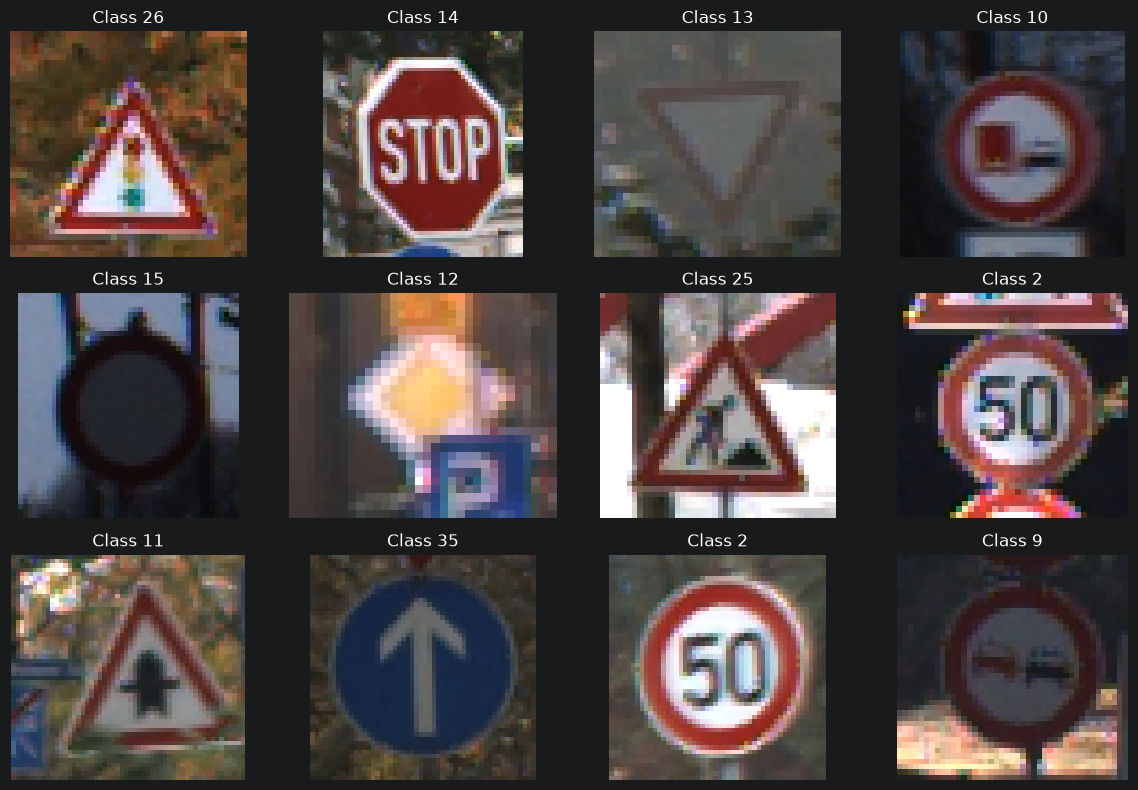

In [9]:
samples = df.sample(
    12,
    random_state=SEED
)

plt.figure(
    figsize=(12, 8)
)

for i, (_, row) in enumerate(
    samples.iterrows()
):

    image_path = (
        DATA_ROOT
        / row["Path"]
    )

    image = Image.open(
        image_path
    ).convert("RGB")

    plt.subplot(
        3,
        4,
        i + 1
    )

    plt.imshow(image)

    plt.title(
        f"Class {row['ClassId']}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

Class distribution

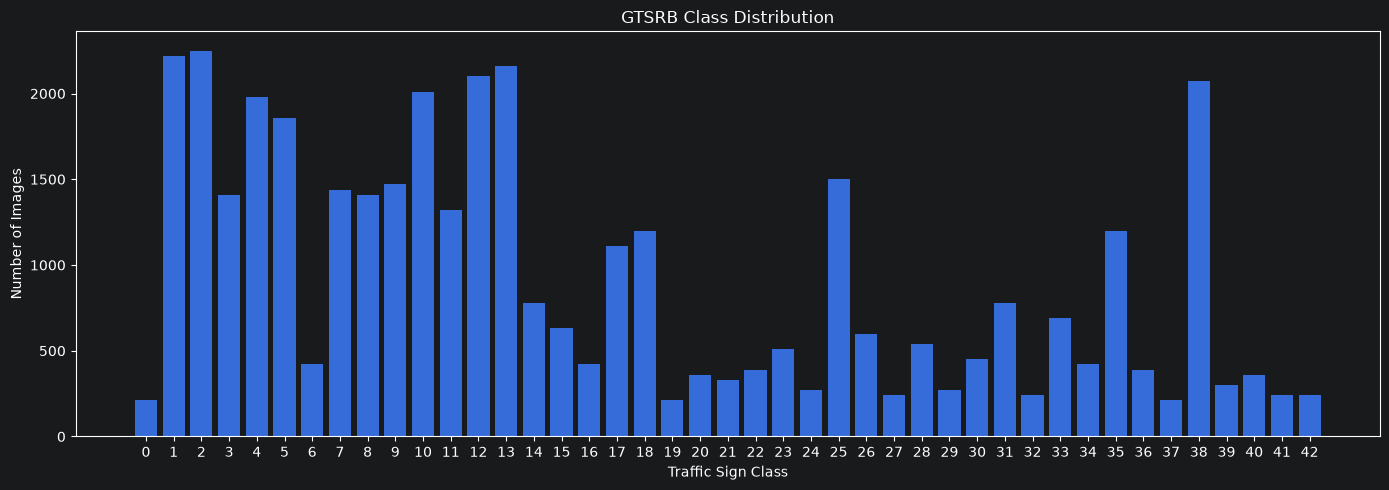

<Figure size 640x480 with 0 Axes>

In [12]:
plt.figure(
    figsize=(14, 5)
)

plt.bar(
    class_counts.index,
    class_counts.values
)

plt.xlabel(
    "Traffic Sign Class"
)

plt.ylabel(
    "Number of Images"
)

plt.title(
    "GTSRB Class Distribution"
)

plt.xticks(
    range(43)
)

plt.tight_layout()
plt.show()

plt.savefig(
    RESULTS_DIR
    / "figures"
    / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

Creating the split

In [20]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["ClassId"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["ClassId"]
)
total = len(df)

print(
    "Training %:",
    len(train_df) / total * 100
)

print(
    "Validation %:",
    len(val_df) / total * 100
)

print(
    "Testing %:",
    len(test_df) / total * 100
)

Training %: 69.99923486954526
Validation %: 14.9991073478028
Testing %: 15.001657782651941


Saving the split

In [21]:
SPLIT_DIR.mkdir(
    exist_ok=True
)

train_df.to_csv(
    SPLIT_DIR / "train_split.csv",
    index=False
)

val_df.to_csv(
    SPLIT_DIR / "val_split.csv",
    index=False
)

test_df.to_csv(
    SPLIT_DIR / "test_split.csv",
    index=False
)

Image Transforms

In [22]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    transforms.RandomRotation(
        degrees=8
    ),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

Custom Dataset Class

In [23]:
class GTSRBDataset(Dataset):

    def __init__(
        self,
        dataframe,
        data_root,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )

        self.data_root = Path(
            data_root
        )

        self.transform = transform

    def __len__(self):

        return len(
            self.dataframe
        )

    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = (
            self.data_root
            / row["Path"]
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        label = int(
            row["ClassId"]
        )

        if self.transform:
            image = self.transform(
                image
            )

        return image, label

Create custom dataset class

In [24]:
train_dataset = GTSRBDataset(
    train_df,
    DATA_ROOT,
    transform=train_transform
)

val_dataset = GTSRBDataset(
    val_df,
    DATA_ROOT,
    transform=eval_transform
)

test_dataset = GTSRBDataset(
    test_df,
    DATA_ROOT,
    transform=eval_transform
)

Create dataset

In [25]:
train_dataset = GTSRBDataset(
    train_df,
    DATA_ROOT,
    transform=train_transform
)

val_dataset = GTSRBDataset(
    val_df,
    DATA_ROOT,
    transform=eval_transform
)

test_dataset = GTSRBDataset(
    test_df,
    DATA_ROOT,
    transform=eval_transform
)

DataLoaders

In [26]:
NUM_WORKERS = 0

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

### Model A

In [30]:
class ModelA(nn.Module):

    def __init__(
        self,
        num_classes=43
    ):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                3,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                128,
                160,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2)
        )

        self.pool = (
            nn.AdaptiveAvgPool2d(
                (1, 1)
            )
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                160,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                128,
                num_classes
            )
        )

    def forward(
        self,
        x
    ):

        x = self.features(x)

        x = self.pool(x)

        x = self.classifier(x)

        return x

In [31]:
model_a = ModelA().to(
    device
)

print(model_a)

ModelA(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 160, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=160, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_feat

In [32]:
def count_parameters(model):

    return sum(
        parameter.numel()
        for parameter
        in model.parameters()
        if parameter.requires_grad
    )

model_a_parameters = (
    count_parameters(
        model_a
    )
)

print(
    "Model A parameters:",
    model_a_parameters
)

Model A parameters: 303883


In [ ]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT)
    )

In [ ]:
from Common.training import (
    train_model,
    create_optimizer
)

from Common.evaluation import (
    get_predictions,
    calculate_metrics,
    plot_training_curves,
    plot_confusion_matrix,
    print_classification_report,
    total_parameters,
    estimated_fp32_size_kb,
    save_model_and_get_size,
    measure_inference_time
)

In [ ]:
selected_optimizer = (
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "selected_optimizer.txt"
).read_text().strip()

print(
    "Selected optimizer:",
    selected_optimizer
)

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

In [ ]:
model_a = ModelA().to(device)

criterion = nn.CrossEntropyLoss()

optimizer_a = create_optimizer(
    selected_optimizer,
    model_a.parameters()
)

print(model_a)

In [ ]:
model_a, history_a = train_model(
    model=model_a,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_a,
    criterion=criterion,
    epochs=30,
    device=device
)

In [ ]:
FIGURES_DIR = (
    PROJECT_ROOT
    / "results"
    / "figures"
)

plot_training_curves(
    history=history_a,
    model_name="Model A",
    save_dir=FIGURES_DIR
)

In [ ]:
y_true_a, y_pred_a = get_predictions(
    model_a,
    test_loader,
    device
)

In [ ]:
metrics_a = calculate_metrics(
    y_true_a,
    y_pred_a
)

print(metrics_a)

In [ ]:
plot_confusion_matrix(
    y_true_a,
    y_pred_a,
    model_name="Model A",
    save_dir=FIGURES_DIR
)

In [ ]:
print_classification_report(
    y_true_a,
    y_pred_a
)

In [ ]:
average_epoch_time_a = np.mean(
    history_a["epoch_time"]
)

print(
    "Average epoch time:",
    average_epoch_time_a,
    "seconds"
)

In [ ]:
parameters_a = total_parameters(
    model_a
)

estimated_size_a = (
    estimated_fp32_size_kb(
        model_a
    )
)

print(
    "Parameters:",
    parameters_a
)

print(
    "Estimated FP32 size:",
    estimated_size_a,
    "KB"
)

In [ ]:
CHECKPOINT_DIR = (
    PROJECT_ROOT
    / "checkpoints"
)

model_a_path = (
    CHECKPOINT_DIR
    / "model_a_final.pth"
)

actual_size_a = (
    save_model_and_get_size(
        model_a,
        model_a_path
    )
)

print(
    "Actual saved model size:",
    actual_size_a,
    "KB"
)

In [ ]:
inference_time_a = measure_inference_time(
    model_a,
    test_loader,
    device
)

print(
    "Inference time:",
    inference_time_a,
    "ms/image"
)

In [ ]:
model_a_results = {
    "Model": "Model A",
    "Parameters": parameters_a,
    "Estimated FP32 Size (KB)": estimated_size_a,
    "Actual Model Size (KB)": actual_size_a,
    "Average Epoch Time (s)": average_epoch_time_a,
    "Inference Time (ms/image)": inference_time_a,
    "Test Accuracy": metrics_a["Test Accuracy"],
    "Macro Precision": metrics_a["Macro Precision"],
    "Macro Recall": metrics_a["Macro Recall"]
}

model_a_df = pd.DataFrame(
    [model_a_results]
)

model_a_df

In [ ]:
METRICS_DIR = (
    PROJECT_ROOT
    / "results"
    / "metrics"
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

model_a_df.to_csv(
    METRICS_DIR / "model_a_metrics.csv",
    index=False
)